In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [3]:
#Criar dados sinteticos seguindo media mu e variancia sigma

rng = np.random.default_rng(seed=42)  # Inicializa o gerador de números aleatórios com uma semente para reprodutibilidade

serie_1 = rng.normal(loc=10, scale=2, size=100)  # Média 10, Variância 4
serie_2 = rng.normal(loc=30, scale=5, size=100)  # Média 30, Variância 25
serie_3 = rng.normal(loc=10, scale=2, size=100)  # Média 10, Variância 4

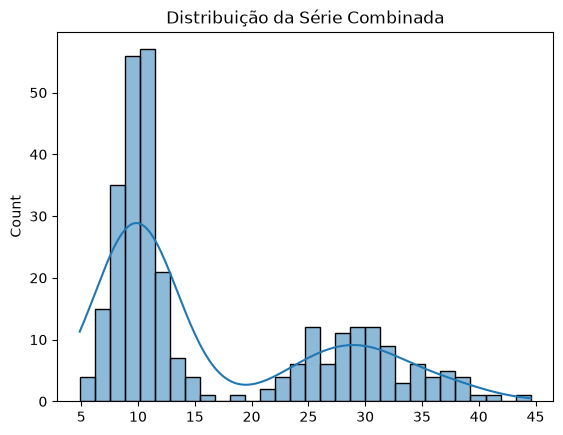

In [4]:
series = np.concatenate([serie_1, serie_2, serie_3])
sns.histplot(series, bins=30, kde=True)
plt.title('Distribuição da Série Combinada')
plt.show()

In [5]:
# Markov Switching Model

model = sm.tsa.MarkovRegression(series, k_regimes=2, trend='c', switching_variance=True)
model_fit = model.fit(maxiter=1000, disp=False, search_reps=20)

In [6]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                        Markov Switching Model Results                        
==============================================================================
Dep. Variable:                      y   No. Observations:                  300
Model:               MarkovRegression   Log Likelihood                -714.832
Date:                Sun, 01 Nov 2026   AIC                           1441.663
Time:                        23:53:42   BIC                           1463.886
Sample:                             0   HQIC                          1450.557
                                - 300                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.8874      0.128     77.294      0.000       9.637      10.138
sigma2         3.2726      0.327     10.000      0.000       2.631       3.914
                             Regime 1 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         29.9468      0.487     61.452      0.000      28.992      30.902
sigma2        23.7471      3.359      7.070      0.000      17.164      30.330
                         Regime transition parameters                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
p[0->0]        0.9962      0.004    249.798      0.000       0.988       1.004
p[1->0]        0.0123      0.010      1.183      0.237      -0.008       0.033
==============================================================================

Warnings:
[1] Covariance matrix calculated using numerical (complex-step) differentiation.
"""

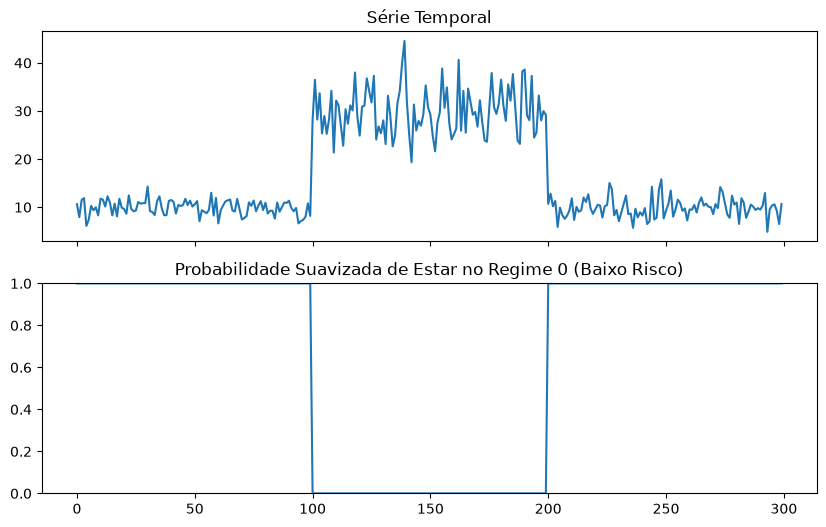

In [7]:
res = model_fit.smoothed_marginal_probabilities[:,0] # probabilidade de estar no regime 0 (baixo risco)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
ax1.plot(series)
ax1.set_title("Série Temporal")
ax2.plot(res)
ax2.set_ylim(0, 1)
ax2.set_title("Probabilidade Suavizada de Estar no Regime 0 (Baixo Risco)")
plt.show()

# Analisando Regimes na série da PTAX

In [ ]:
import sys
sys.path.append("../..")
from src.bcb import buscar_serie, json_para_dataframe, URL

In [9]:
help(buscar_serie)

dados_ptax = buscar_serie(URL, '01/01/2016', '31/12/2025', timeout=60)

Help on function buscar_serie in module src.bcb:

buscar_serie(
    url: str,
    data_inicio: str = '01/01/2024',
    data_fim: str = '31/03/2024',
    timeout: float = 10
) -> list
    Busca JSON na API do BCB. Falha alto se a rede ou o servidor falhar



In [10]:
# Transformando os dados JSON em um DataFrame do Pandas
ptax_df = json_para_dataframe(dados_ptax)
ptax_df['retorno'] = ptax_df['valor'].pct_change()*100  # Calculando o retorno percentual diário
ptax_df.head()

,data,valor,retorno
0,2016-01-04,4.0387,NaN
1,2016-01-05,4.0114,-0.675960
2,2016-01-06,4.0303,0.471157
3,2016-01-07,4.0475,0.426767
4,2016-01-08,4.0250,-0.555899


In [11]:
ptax_df = ptax_df.dropna()  # Removendo valores NaN resultantes do cálculo de retorno

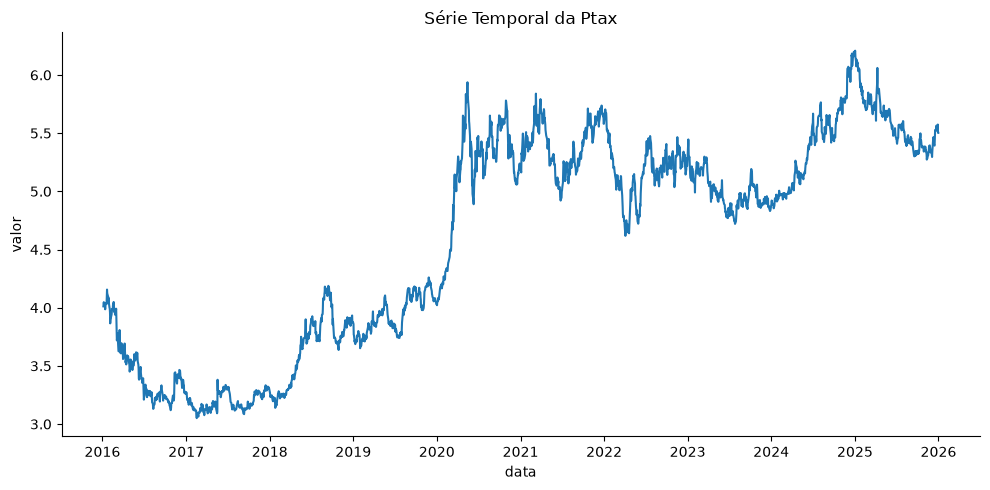

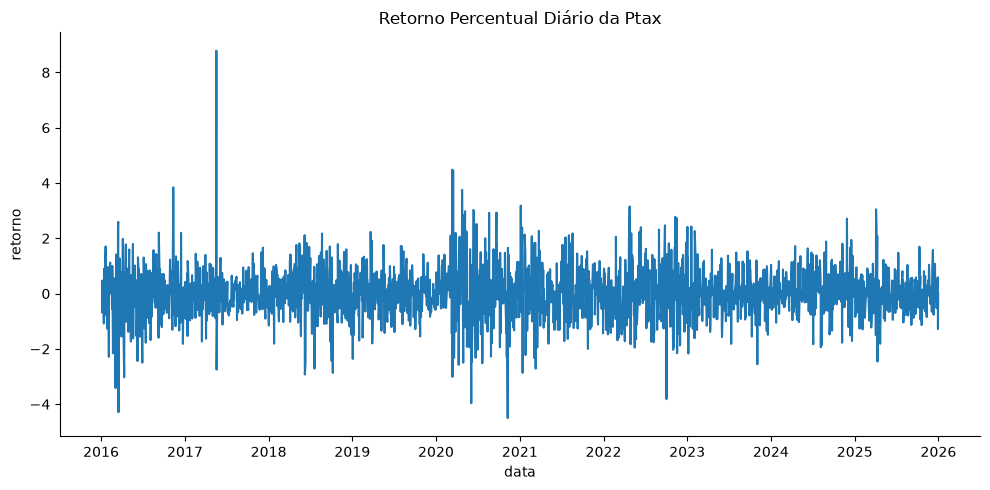

In [12]:
# Visualizando os dados
sns.relplot(data=ptax_df, x='data', y='valor', kind='line', aspect = 2)
plt.title('Série Temporal da Ptax')
plt.tight_layout()
plt.show()

sns.relplot(data=ptax_df, x='data', y='retorno', kind='line', aspect = 2)
plt.title('Retorno Percentual Diário da Ptax')
plt.tight_layout()
plt.show()

In [13]:
# Modelo de Markov Switching para a série Ptax
model_ptax = sm.tsa.MarkovRegression(ptax_df['retorno'], k_regimes=2, trend='c', switching_variance=True)
model_ptax_fit = model_ptax.fit(maxiter=1000, disp=False, search_reps=20)

In [14]:
model_ptax_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                        Markov Switching Model Results                        
==============================================================================
Dep. Variable:                retorno   No. Observations:                 2509
Model:               MarkovRegression   Log Likelihood               -3082.798
Date:                Sun, 01 Nov 2026   AIC                           6177.596
Time:                        23:54:03   BIC                           6212.562
Sample:                             0   HQIC                          6190.288
                               - 2509                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0019      0.017      0.113      0.910      -0.031       0.035
sigma2         0.4099      0.021     19.820      0.000       0.369       0.450
                             Regime 1 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0473      0.047      1.000      0.318      -0.045       0.140
sigma2         1.6280      0.117     13.970      0.000       1.400       1.856
                         Regime transition parameters                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
p[0->0]        0.9851      0.005    183.467      0.000       0.975       0.996
p[1->0]        0.0327      0.013      2.559      0.010       0.008       0.058
==============================================================================

Warnings:
[1] Covariance matrix calculated using numerical (complex-step) differentiation.
"""

Note que as médias não são significativas, o que nos leva a conclusão que o regime é majoritariamente definido pela diferença de volatilidade.

In [15]:
model_ptax_fit.params

p[0->0]      0.985088
p[1->0]      0.032697
const[0]     0.001897
const[1]     0.047339
sigma2[0]    0.409909
sigma2[1]    1.628020
dtype: float64

Aqui vemos que o tempo médio de se manter no regime 1 é de $\frac{1}{0.0326} = 31\ dias $

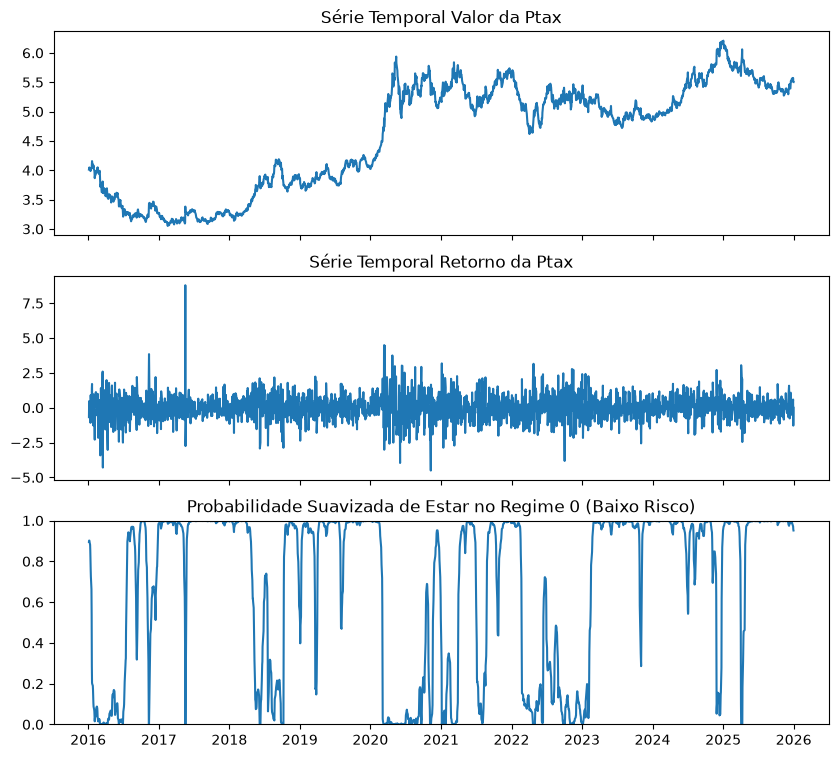

In [16]:
res = model_ptax_fit.smoothed_marginal_probabilities[0]  # probabilidade de estar no regime 0 (baixo risco)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 9))
ax1.plot(ptax_df['data'], ptax_df['valor'])
ax1.set_title("Série Temporal Valor da Ptax")
ax2.plot(ptax_df['data'], ptax_df['retorno'])
ax2.set_title("Série Temporal Retorno da Ptax")
ax3.plot(ptax_df['data'], res)
ax3.set_ylim(0, 1)
ax3.set_title("Probabilidade Suavizada de Estar no Regime 0 (Baixo Risco)")
plt.show()

Como leitura das probabilidades de regime, tome como exemplo três pontos: 2016, 2018 e 2020.

2016: Em 2016 ocorreu o impeatchment da então presidente Dilma, o que fez com que investidores externos tivessem aversão ao risco Brasil, retirando capital estrangeiro da economia. O valor do dólar já vinha caindo pois investidores acreditavam na troca de governo. É importante ressaltar que o modelo detecta volatilidade, não direção, o preço subindo e caindo podem estar no mesmo regime desde que a volatilidade seja parecida.

2018: O segundo semestre de 2018 mostra aumento de volatilidade da PTAX, isso ocorreu junto com o calendário eleitoral brasileiro. As eleições presidenciais entre Fernando Hadaad e Jair Bolsonaro ditaram o comportamento do dólar. A eleição presidencial é um fator importante para a economia pois investidores se importam com política fiscal e risco de default de seus invetimentos. Com governos onde as medidas de controle de gastos e ajustes fiscais são nebulosas, o mercado externo prefere não se arriscar e retirar o dinheiro do país. Outro ponto importante em 2018, foi a greve dos caminhoneiros, em maio.

2020: No primeiro trimestre de 2020 foi anunciada a pandemia de COVID-19, o cenário econômico global estava abalado e o impacto na relação real-dólar é evidente. O período de alta volatilidade do dólar continuou durante todo o ano de 2020 e foi capturado pelo modelo.

# Walk-foward

Até agora, usamos todos os dados para treinar o modelo, isso é vazamento de dados. O que vamos implementar agora é um método de walk-foward, para avaliar se o modelo consegue prever bem o regime em `t+1` apenas com os dados até `t`.

A função `fitered_marginal_probabilities` utiliza dados somente até `t` $P(S_T | y_1, ... , y_t) $
enquanto `smoothed_marginal_probabilities` utiliza todos os dados $P(S_T | y_1, ... , y_T)$

Mesmo utilizando a função filtrada, nossas médias e variâncias foram calculadas utilizando o conjunto completo de dados. O treino só cresce e o ponto previsto é sempre fora da amostra.

O custo dessa abordagem é que reajustar o modelo todo dia aumenta muito a quantidade de fits, o que deixa o treinamento lento. Vamos reajustar uma vez por mês.

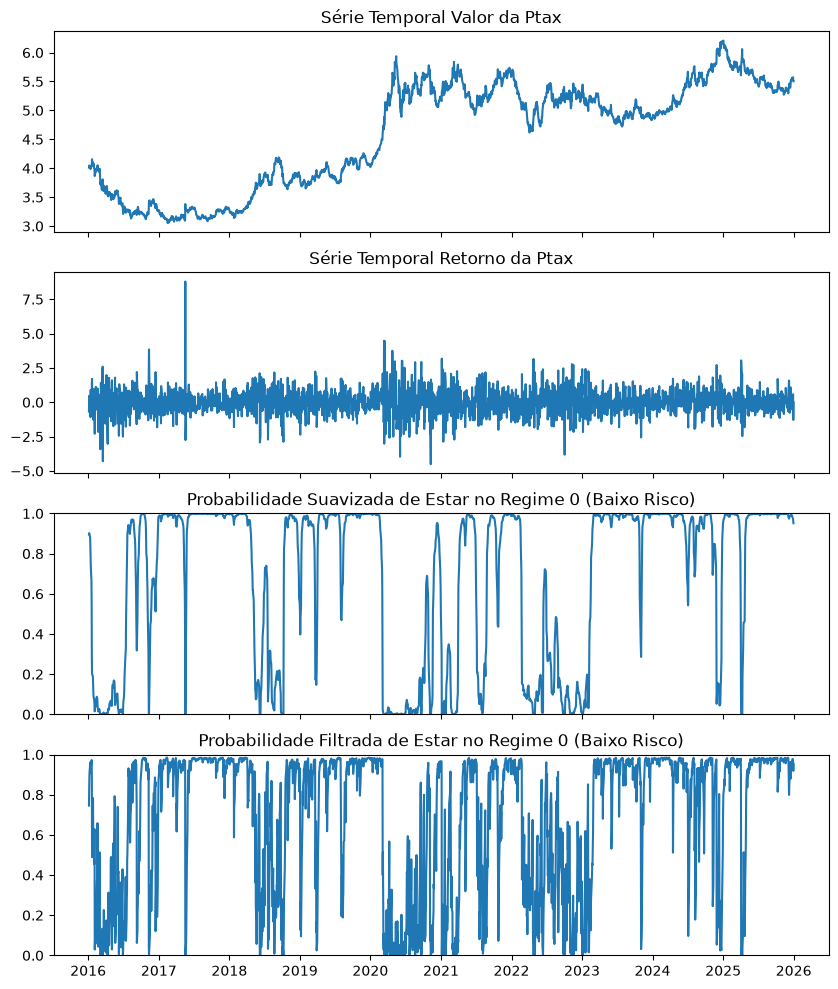

In [17]:
# Visualizando as probabilidades suavizadas e filtradas de cada regime.

res = model_ptax_fit.smoothed_marginal_probabilities[0]  # probabilidade de estar no regime 0 (baixo risco)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=True, figsize=(10, 12))
ax1.plot(ptax_df['data'], ptax_df['valor'])
ax1.set_title("Série Temporal Valor da Ptax")
ax2.plot(ptax_df['data'], ptax_df['retorno'])
ax2.set_title("Série Temporal Retorno da Ptax")
ax3.plot(ptax_df['data'], res)
ax3.set_ylim(0, 1)
ax3.set_title("Probabilidade Suavizada de Estar no Regime 0 (Baixo Risco)")
ax4.plot(ptax_df['data'], model_ptax_fit.filtered_marginal_probabilities[0])
ax4.set_ylim(0, 1)
ax4.set_title("Probabilidade Filtrada de Estar no Regime 0 (Baixo Risco)")
plt.show()

Note que a probabilidade filtrada oscila muito em 2020, enquanto a suavizada mantem 2020 quase inteiro no regime de alta volatilidade com probabilidade alta.

In [18]:
# WFA manualmente
dados_treino = ptax_df[ptax_df['data'] < '2020-01-01']
dados_teste = ptax_df[(ptax_df['data'] >= '2020-01-01') & (ptax_df['data'] < '2021-01-01')]

model_ptax_wfa = sm.tsa.MarkovRegression(dados_treino['retorno'], k_regimes=2, trend='c', switching_variance=True)
model_ptax_wfa_fit = model_ptax_wfa.fit(maxiter=1000, disp=False, search_reps=20)
print(model_ptax_wfa_fit.summary())
print(model_ptax_wfa_fit.params)

                        Markov Switching Model Results                        
Dep. Variable:                retorno   No. Observations:                 1002
Model:               MarkovRegression   Log Likelihood               -1189.120
Date:                Sun, 01 Nov 2026   AIC                           2390.239
Time:                        23:54:04   BIC                           2419.698
Sample:                             0   HQIC                          2401.434
                               - 1002                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0248      0.024      1.021      0.307      -0.023       0.072
sigma2         0.4892      0.034     14.433      0.0

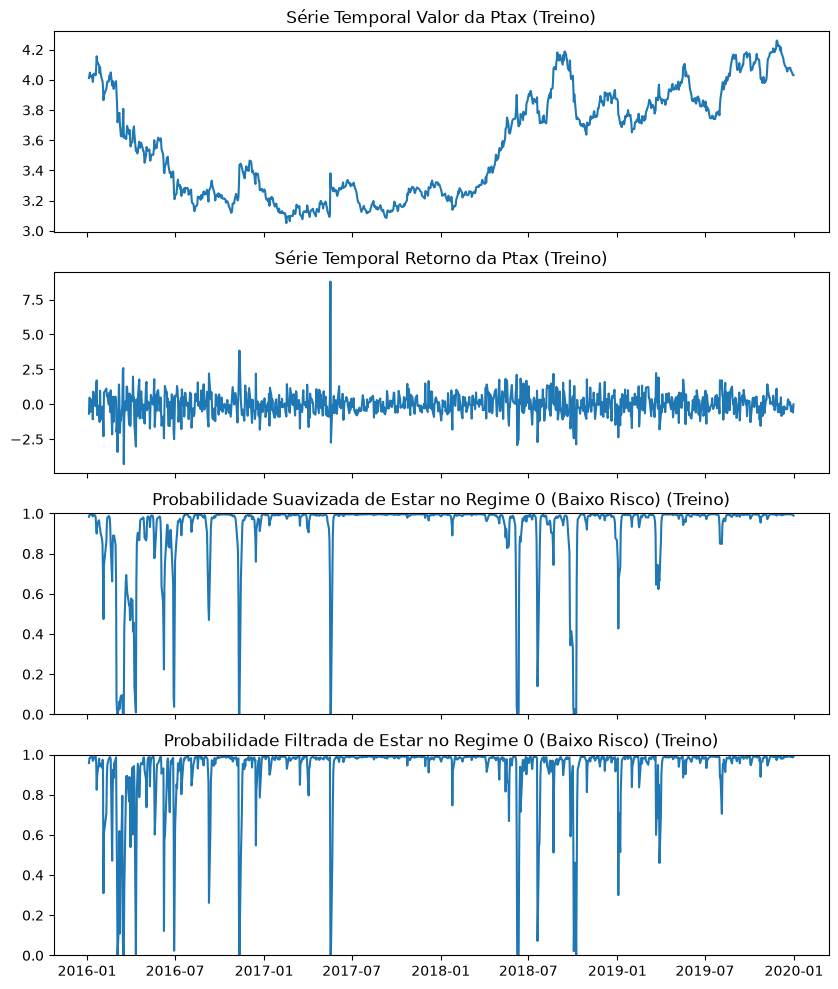

In [19]:
# Visualização das probabilidades suavizadas e filtradas de cada regime para o modelo WFA
res_wfa = model_ptax_wfa_fit.smoothed_marginal_probabilities[0]  # probabilidade de estar no regime 0 (baixo risco)
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=True, figsize=(10, 12))
ax1.plot(dados_treino['data'], dados_treino['valor'])
ax1.set_title("Série Temporal Valor da Ptax (Treino)")
ax2.plot(dados_treino['data'], dados_treino['retorno'])
ax2.set_title("Série Temporal Retorno da Ptax (Treino)")
ax3.plot(dados_treino['data'], res_wfa)
ax3.set_ylim(0, 1)
ax3.set_title("Probabilidade Suavizada de Estar no Regime 0 (Baixo Risco) (Treino)")
ax4.plot(dados_treino['data'], model_ptax_wfa_fit.filtered_marginal_probabilities[0])
ax4.set_ylim(0, 1)
ax4.set_title("Probabilidade Filtrada de Estar no Regime 0 (Baixo Risco) (Treino)")
plt.show()

Note que o modelo com dados até 2020 é diferente do modelo treinado com os 10 anos. O regime 0 continua sendo o calmo, com variância de 0.49 (~0.7% desvio ao dia). O regime 1 tem variância de 3.9% (desvio de aproximadamente 2%) e probabilidade de se manter no regime 1 ($p_{11}= 1-0.2535 = 0.75$). Isso da uma duração média de $\frac{1}{0.2535} = 4\ dias $

Com os dados até o fim de 2019, nosso modelo considera o regime de estresse, pequenos choques na volatilidade do dólar, como por exemplo, em maio de 2018 em que o áudio de Temer com a JBS foi vazado.

O modelo até aqui não viu períodos longos de volatilidade. O que o modelo entende por "regime" depende do que ele "viu" e isso se chama instabilidade de parâmetros.

/home/tiago_msl/Projects/portfolio_data_science/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


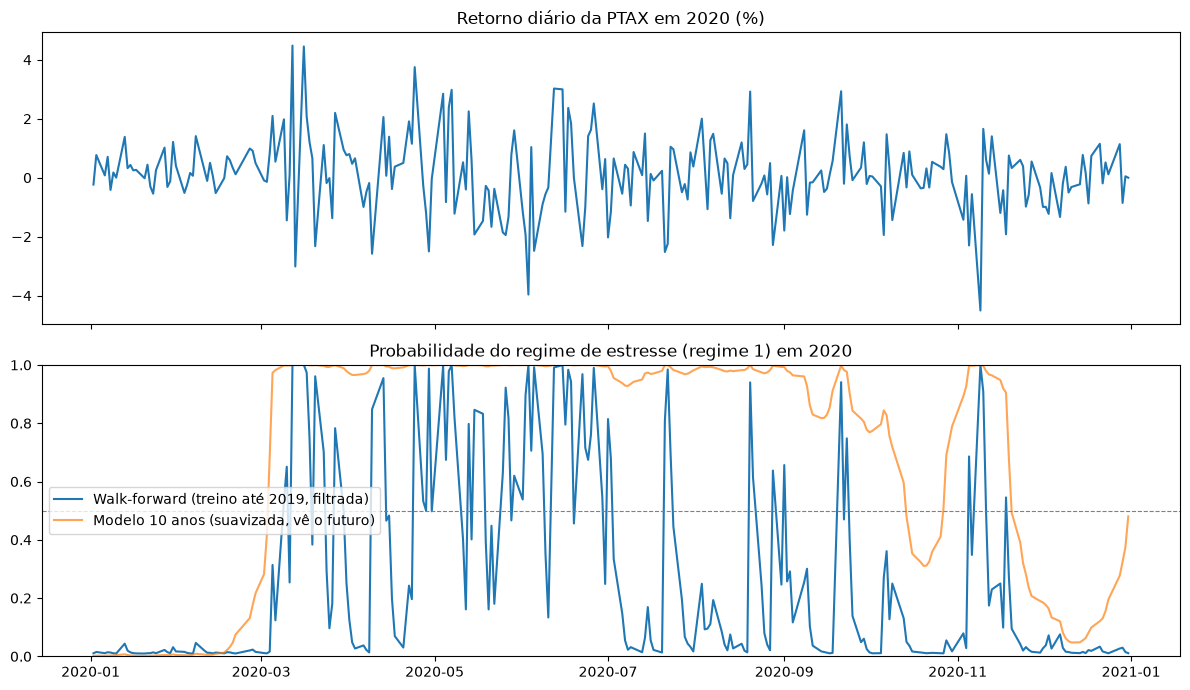

In [20]:
# Série com data como index (o alinhamento por data substitui os índices "na mão")
retorno = ptax_df.set_index('data')['retorno'].loc[:'2020-12-31']

# Modelo out-of-sample: parâmetros de 2019 aplicados até 2020, sem reestimar
modelo_2020 = sm.tsa.MarkovRegression(retorno, k_regimes=2, trend='c', switching_variance=True)
filtrado_2020 = modelo_2020.filter(model_ptax_wfa_fit.params)
prob_estresse_wfa = filtrado_2020.filtered_marginal_probabilities[1].loc['2020']

# Modelo de 10 anos (in-sample, "sabe o futuro") para comparação
prob_estresse_full = model_ptax_fit.smoothed_marginal_probabilities[1]
prob_estresse_full.index = ptax_df['data'].iloc[-len(prob_estresse_full):].values # definindo indice de datas para a série de probabilidades suavizadas
prob_estresse_full = prob_estresse_full.loc['2020']

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12, 7))

ax1.plot(retorno.loc['2020'])
ax1.set_title("Retorno diário da PTAX em 2020 (%)")

ax2.plot(prob_estresse_wfa, label="Walk-forward (treino até 2019, filtrada)")
ax2.plot(prob_estresse_full, label="Modelo 10 anos (suavizada, vê o futuro)", alpha=0.7)
ax2.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
ax2.set_ylim(0, 1)
ax2.set_title("Probabilidade do regime de estresse (regime 1) em 2020")
ax2.legend() # mostra a legenda de label

plt.tight_layout()
plt.show()

Note que o modelo de 10 anos de dados mantem 2020 quase por inteiro com mais de 50% de probabilidade de estar no regime de estresse, enquanto o modelo que viu dados até 2019 oscila o ano inteiro entre regime calmo e de estresse. Vemos o tempo médio de 4 dias do modelo refletido nos picos abruptos no modelo com dados até 2019.

A curva do modelo completo é mais suavizada pois ja viram os dados do futuro, isso superestima os parâmetros do modelo, temos que tomar cuidado com vazamento de dados no treinamento pois isso pode gerar resultados enganosos que quebram em produção. No nosso exemplo, esse vazamento de dados faz com que um dia calmo seja classificado como volátil pois o modelo sabe que nos dias seguintes as volatilidade irá voltar.



# Transformando WFA em um Loop

In [21]:
# funcao WFA

def wfa_markov_regimes(data, inicio_teste='2021-01-01', search_reps=5):
    """
    Função para realizar Walk-Forward Analysis (WFA) usando o modelo de Markov Switching.
    
    Parâmetros:
    data (pd.DataFrame): DataFrame contendo a série temporal com colunas 'data' e 'retorno'.
    inicio_teste (str): Data de início para o teste.
    search_reps (int): Número de repetições para a busca de parâmetros no ajuste do modelo.
    
    Retorna:
    pd.Series: Series contendo as probabilidades filtradas do regime de estresse para cada período de teste.
    """
    required_cols = ["data", "retorno"]
    for col in required_cols:
        if col not in data.columns:
            raise ValueError(f"A coluna '{col}' é obrigatória no DataFrame de entrada.")

    # Inicializando uma lista para armazenar os resultados
    resultados = []

    # Definindo os períodos de treino e teste
    retorno = data.set_index('data')['retorno']
    # Gerando uma lista de datas de início de cada mês a partir do início do teste até o final da série
    meses = pd.date_range(inicio_teste, retorno.index.max(), freq='MS')

    for inicio in meses:
        fim = inicio + pd.offsets.MonthEnd(0)

        # os dados de treino do modelo devem ser todos os dados anteriores ao início do mês de teste
        treino = retorno[retorno.index < inicio]
        # os dados de teste do modelo são todos os dados até o final do mês de teste
        serie_ate_fim_mes = retorno.loc[:fim]

        # Ajustamos o modelo com os dados de treino e coletamos os parâmetros estimados
        params = sm.tsa.MarkovRegression(treino, k_regimes=2, trend='c',
                                        switching_variance=True).fit(maxiter=1000, disp=False, search_reps=search_reps).params

        # descobrindo qual regime é o de estresse (maior variância)
        estresse = 1 if params['sigma2[1]'] > params['sigma2[0]'] else 0

        # Aplicamos o modelo com os parâmetros estimados no treino e calculamos as probabilidades filtradas para o período de teste
        filtrado = sm.tsa.MarkovRegression(serie_ate_fim_mes, k_regimes=2, trend='c',
                                        switching_variance=True).filter(params)

        # coletamos as probabilidades do regime de estresse para o periodo de teste (inicio a fim) e adicionamos à lista de resultados
        # note que inicio:fim é um slice de 1 mês. Para cada passo de um mês vamos ajustando o modelo com os novos dados e prevendo o próximo.
        prob_mes = filtrado.filtered_marginal_probabilities[estresse].loc[inicio:fim]
        resultados.append(prob_mes)

    # o concat fora do loop reduz o tempo de execução, pois concatena todos os resultados de uma vez, em vez de concatenar a cada iteração do loop.
    return pd.concat(resultados)



In [22]:
resultados_wfa = wfa_markov_regimes(ptax_df, inicio_teste='2020-01-01', search_reps=5)

/home/tiago_msl/Projects/portfolio_data_science/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/tiago_msl/Projects/portfolio_data_science/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/tiago_msl/Projects/portfolio_data_science/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/tiago_msl/Projects/portfolio_data_science/.venv/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:4

In [23]:
resultados_wfa

data
2020-01-02    0.010686
2020-01-03    0.015179
2020-01-06    0.011014
2020-01-07    0.014251
2020-01-08    0.013204
                ...   
2025-12-24    0.030066
2025-12-26    0.022869
2025-12-29    0.026316
2025-12-30    0.084236
2025-12-31    0.050211
Length: 1507, dtype: float64

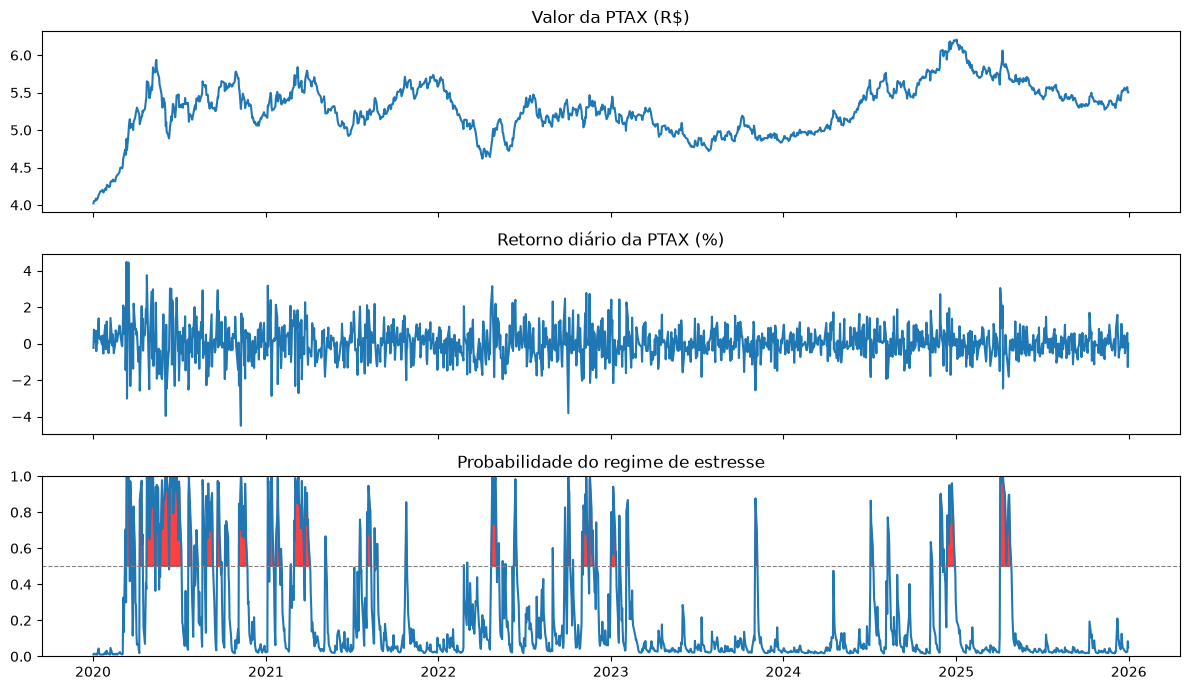

In [24]:
# Série com data como index (o alinhamento por data substitui os índices "na mão")
retorno = ptax_df.set_index('data')['retorno'].loc['2020-01-01':]
valores = ptax_df.set_index('data')['valor'].loc['2020-01-01':]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(12, 7))

ax1.plot(valores)
ax1.set_title("Valor da PTAX (R$)")

ax2.plot(retorno)
ax2.set_title("Retorno diário da PTAX (%)")

ax3.plot(resultados_wfa, label="Walk-forward (mensal, filtrada)")
ax3.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
ax3.set_ylim(0, 1)
ax3.set_title("Probabilidade do regime de estresse")
ax3.fill_between(
    resultados_wfa.index,
    resultados_wfa,
    0.5,
    where=(resultados_wfa > 0.5),
    color='red',
    alpha=0.75,
    interpolate=True
)

plt.tight_layout()
plt.show()

Note o ano de 2020, usando o WFA, o modelo mantém por mais tempo a probabilidade de regime de estresse acima de 50%. Isso ocorre pois o modelo aprende mês após mês que tempos mais longos de estresse podem ocorrer.

Em 2022 podemos ver o efeito das eleições novamente no final do ano. Mas 2023 a 2024 tivemos periodo majoritariamente calmo com poucos picos de volatilidade.

No inicio de 2025 tivemos um periodo de alta volatilidade no dólar, o que pode estar relacionado a relações diplomáticas com EUA (sanções aplicadas a ministros do STF), julgamento de Jair Bolsonaro e o tarifaço de Trump.

# Calibração

Vamos definir um limite do que é um dia de estresse, olhando 3 abordagens: média de 5 dias, percentil 95% de 5 dias, ancorado no modelo (a vol onde calmo e estresse são igualmente verossimel)

O alvo aqui ($y_t$) é binário: 1 se a volatilidade dos 5 dias seguintes passarem de um LIMIAR e 0 caso contrário.

In [25]:
from sklearn.calibration import calibration_curve

In [76]:
retorno = ptax_df.set_index('data')['retorno']

# calculando a volatilidade futura (desvio padrão dos próximos 5 dias) e o regime de estresse (1 se vol futura > limite, 0 caso contrário)
vol_futura = retorno.rolling(5).std().shift(-5)
# O rolling(5).std() calcula o desvio de 5 em 5 dias, e o shift(-5) traz o valor do futuro para o dia de hoje.
vol_treino = vol_futura.loc[:'2019']
vol_teste = vol_futura.loc['2020':]

limite_media = vol_treino.mean()           # A
limite_p95   = vol_treino.quantile(0.95)   # B
limite_p75 = vol_treino.quantile(0.75)   # B2
limite_p80 = vol_treino.quantile(0.80)   # B3
limite_p90 = vol_treino.quantile(0.90)   # B4

print(f"Limite de estresse (média): {limite_media:.4f}")
print(f"Limite de estresse (p95): {limite_p95:.4f}")
print(f"Limite de estresse (p75): {limite_p75:.4f}")
print(f"Limite de estresse (p80): {limite_p80:.4f}")
print(f"Limite de estresse (p90): {limite_p90:.4f}")

estresse_media = (vol_teste > limite_media).astype(int)
estresse_p95   = (vol_teste > limite_p95).astype(int)
estresse_p75 = (vol_teste > limite_p75).astype(int)
estresse_p80 = (vol_teste > limite_p80).astype(int)
estresse_p90 = (vol_teste > limite_p90).astype(int)

tabela = pd.DataFrame({'prob': resultados_wfa, 'media': estresse_media, 'p95': estresse_p95, 'p75': estresse_p75, 'p80': estresse_p80, 'p90': estresse_p90}).dropna()
tabela['faixa'] = pd.cut(tabela['prob'], bins=[0, .2, .4, .6, .8, 1])
tabela.groupby('faixa').agg({'prob': 'mean', 'media': 'mean', 'p95': 'mean', 'p75': 'mean', 'p80': 'mean', 'p90': 'mean', 'faixa': 'count'}).rename(columns={'faixa': 'count'})

Limite de estresse (média): 0.7406
Limite de estresse (p95): 1.4272
Limite de estresse (p75): 0.8947
Limite de estresse (p80): 0.9614
Limite de estresse (p90): 1.2011


,prob,media,p95,p75,p80,p90,count
faixa,,,,,,,
"(0.0, 0.2]",0.057412,0.350140,0.041083,0.220355,0.176471,0.100840,1071
"(0.2, 0.4]",0.292643,0.648855,0.106870,0.473282,0.389313,0.206107,131
"(0.4, 0.6]",0.489133,0.560976,0.097561,0.341463,0.292683,0.134146,82
"(0.6, 0.8]",0.689853,0.659341,0.164835,0.494505,0.472527,0.296703,91
"(0.8, 1.0]",0.921902,0.750000,0.325758,0.651515,0.628788,0.439394,132


In [77]:
brier_media = ((tabela['prob'] - tabela['media'])**2).mean()
taxa_media = tabela['media'].mean()
brier_base_media = ((taxa_media - tabela['media'])**2).mean()
brier_p95   = ((tabela['prob'] - tabela['p95'])**2).mean()
taxa_p95   = tabela['p95'].mean()
brier_base_p95 = ((taxa_p95 - tabela['p95'])**2).mean()
taxa_p75   = tabela['p75'].mean()
brier_p75   = ((tabela['prob'] - tabela['p75'])**2).mean()
brier_base_p75 = ((taxa_p75 - tabela['p75'])**2).mean()
taxa_p80   = tabela['p80'].mean()
brier_p80   = ((tabela['prob'] - tabela['p80'])**2).mean()
brier_base_p80 = ((taxa_p80 - tabela['p80'])**2).mean()
taxa_p90   = tabela['p90'].mean()
brier_p90   = ((tabela['prob'] - tabela['p90'])**2).mean()
brier_base_p90 = ((taxa_p90 - tabela['p90'])**2).mean()

print("Quanto menor o Brier Score, melhor a previsão probabilística do modelo.")
print(f"Brier Score (média): {brier_media:.4f}")
print(f"Brier Score (base - média): {brier_base_media:.4f}")
print(f"Brier Score (p95): {brier_p95:.4f}")
print(f"Brier Score (base - p95): {brier_base_p95:.4f}")
print(f"Brier Score (p75): {brier_p75:.4f}")
print(f"Brier Score (base - p75): {brier_base_p75:.4f}")
print(f"Brier Score (p80): {brier_p80:.4f}")
print(f"Brier Score (base - p80): {brier_base_p80:.4f}")
print(f"Brier Score (p90): {brier_p90:.4f}")
print(f"Brier Score (base - p90): {brier_base_p90:.4f}")


Quanto menor o Brier Score, melhor a previsão probabilística do modelo.
Brier Score (média): 0.2935
Brier Score (base - média): 0.2466
Brier Score (p95): 0.1277
Brier Score (base - p95): 0.0755
Brier Score (p75): 0.2177
Brier Score (base - p75): 0.2113
Brier Score (p80): 0.1900
Brier Score (base - p80): 0.1918
Brier Score (p90): 0.1557
Brier Score (base - p90): 0.1298


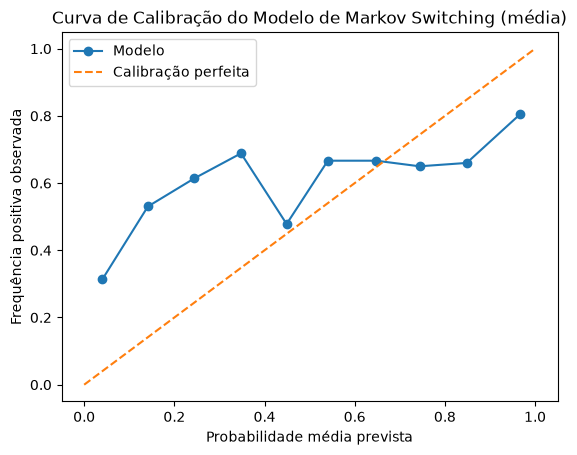

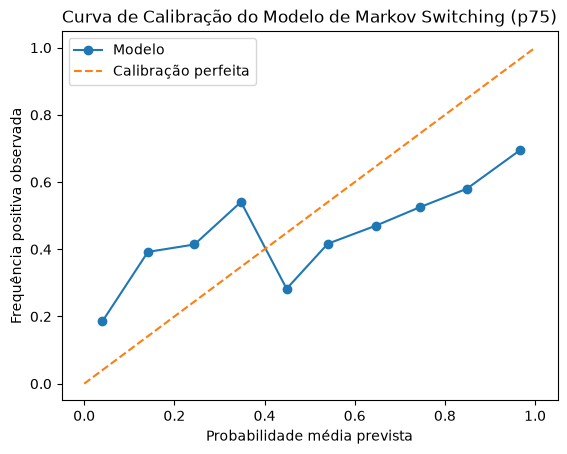

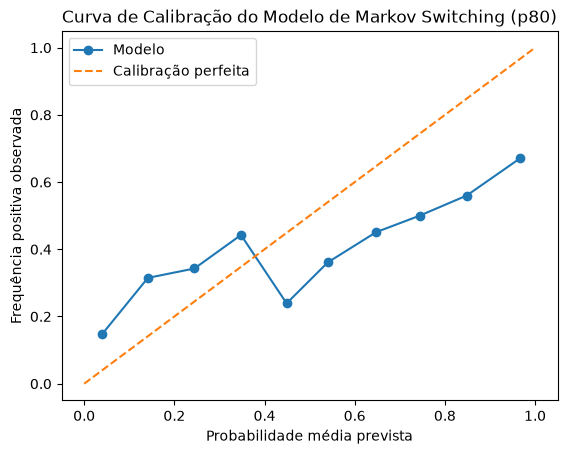

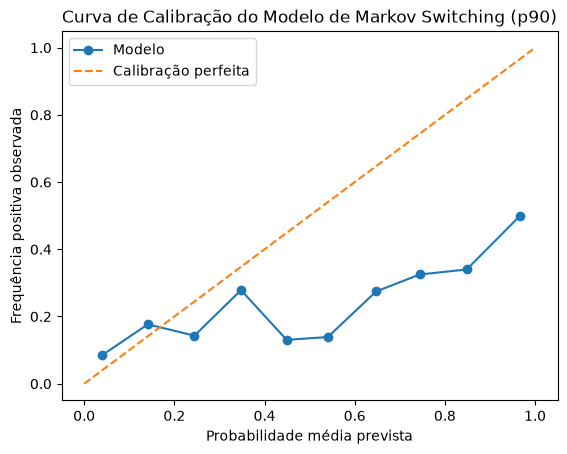

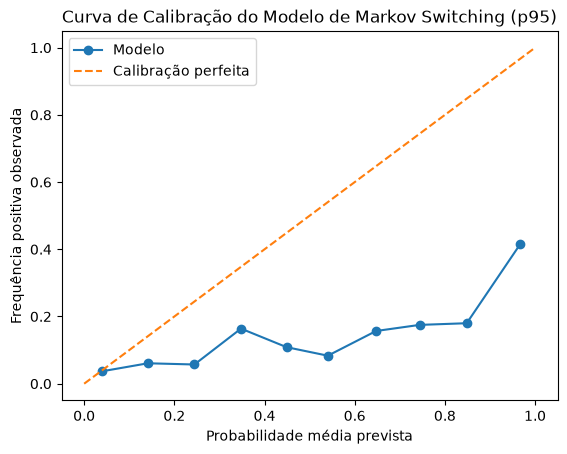

In [79]:
prob_true, prob_pred = calibration_curve(tabela['media'], tabela['prob'], n_bins=10)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.title("Curva de Calibração do Modelo de Markov Switching (média)")
plt.show()

prob_true, prob_pred = calibration_curve(tabela['p75'], tabela['prob'], n_bins=10)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.title("Curva de Calibração do Modelo de Markov Switching (p75)")
plt.show()

prob_true, prob_pred = calibration_curve(tabela['p80'], tabela['prob'], n_bins=10)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.title("Curva de Calibração do Modelo de Markov Switching (p80)")
plt.show()

prob_true, prob_pred = calibration_curve(tabela['p90'], tabela['prob'], n_bins=10)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.title("Curva de Calibração do Modelo de Markov Switching (p90)")
plt.show()

prob_true, prob_pred = calibration_curve(tabela['p95'], tabela['prob'], n_bins=10)

plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração perfeita")
plt.legend()
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência positiva observada")
plt.title("Curva de Calibração do Modelo de Markov Switching (p95)")
plt.show()

Abordagem C: os dois desvios do modelo, o calmo ($s_0$) e o agitado ($s_1$). O limite é o ponto em que um dia é igualmente provável nos dois regimes, ou seja, onde as duas curvas normais se cruzam. É isso que a fórmula faz, e nada mais.

In [ ]:
# Abordagem C: limite ancorado no modelo treinado até 2019
# Ideia: o ponto em que um dia é igualmente provável no regime calmo e no agitado,
# ou seja, onde as duas curvas normais N(0, s0²) e N(0, s1²) se cruzam.

def limite_ancorado(s0, s1):
    """s0 = desvio do regime calmo, s1 = desvio do regime de estresse."""
    return np.sqrt(2 * np.log(s1 / s0) * s0**2 * s1**2 / (s1**2 - s0**2))

# Desvios dos dois regimes (raiz da variância), do menor para o maior
variancias = sorted([model_ptax_wfa_fit.params['sigma2[0]'],
                     model_ptax_wfa_fit.params['sigma2[1]']])
s0, s1 = np.sqrt(variancias[0]), np.sqrt(variancias[1])

limite_c = limite_ancorado(s0, s1)
print(f"Desvio calmo: {s0:.4f} | Desvio estresse: {s1:.4f}")
print(f"Limite de estresse (ancorado): {limite_c:.4f}")


estresse_c = (vol_teste > limite_c).astype(int)
tabela['ancorado'] = estresse_c

taxa_c = tabela['ancorado'].mean()
brier_c = ((tabela['prob'] - tabela['ancorado'])**2).mean()
brier_base_c = ((taxa_c - tabela['ancorado'])**2).mean()

print(f"Brier Score (ancorado): {brier_c:.4f}")
print(f"Brier Score (base - ancorado): {brier_base_c:.4f}")

Desvio calmo: 0.6994 | Desvio estresse: 1.9757
Limite de estresse (ancorado): 1.0777
Brier Score (ancorado): 0.1704
Brier Score (base - ancorado): 0.1626
